# RFM Customer Segmentation

Log-transform and standardize customer RFM metrics, compare candidate cluster counts, fit a four-cluster K-Means model, and save profiles and visuals.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.segmentation import (
    SEGMENTS_PATH, evaluate_cluster_counts, fit_rfm_segments,
    prepare_rfm, save_optimal_k_plot, save_segment_figures,
)

rfm = pd.read_parquet(ROOT / 'data/interim/rfm.parquet')
scaled_rfm, scaler = prepare_rfm(rfm)
rfm.shape, rfm.describe().round(1)

((4338, 4),
        customer_id  recency  frequency  monetary
 count       4338.0   4338.0     4338.0    4338.0
 mean       15300.4     93.1        4.3    2054.3
 std         1721.8    100.0        7.7    8989.2
 min        12346.0      1.0        1.0       3.8
 25%        13813.2     18.0        1.0     307.4
 50%        15299.5     51.0        2.0     674.5
 75%        16778.8    142.8        5.0    1661.7
 max        18287.0    374.0      209.0  280206.0)

## Select cluster count

Review inertia and silhouette diagnostics across k=2..10. The project uses k=4 to keep the customer segments actionable.

,k,inertia,silhouette
0,2,6474.146444,0.432624
1,3,4856.585522,0.336401
2,4,3924.459699,0.335547
3,5,3268.211919,0.318192
4,6,2840.151416,0.315561
5,7,2533.024427,0.310149
6,8,2325.523036,0.301952
7,9,2145.038664,0.281159
8,10,1990.130718,0.276272


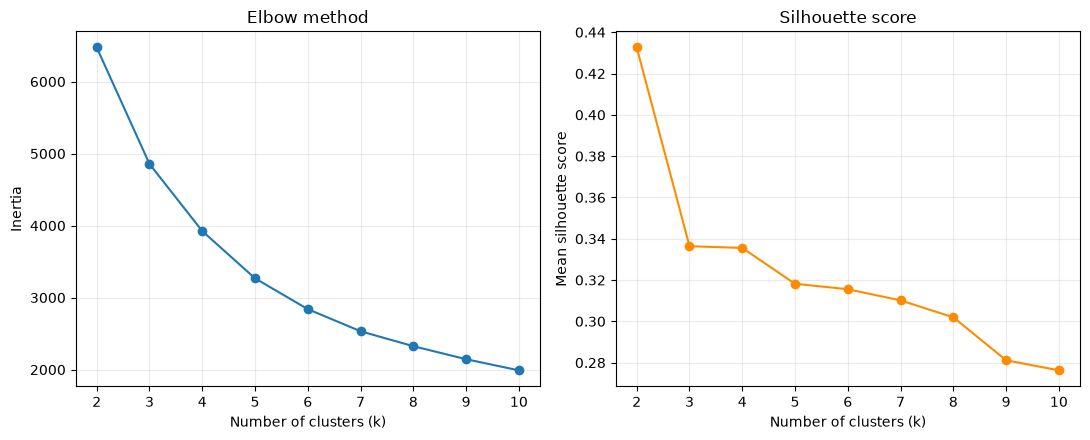

In [2]:
cluster_scores = evaluate_cluster_counts(scaled_rfm, range(2, 11))
optimal_k_path = save_optimal_k_plot(cluster_scores)
display(cluster_scores)
display(Image(filename=str(optimal_k_path)))

## Fit segments and profile customers

In [3]:
segments, segment_profile, scaler, kmeans = fit_rfm_segments(
    rfm, n_clusters=4, random_state=42
)
SEGMENTS_PATH.parent.mkdir(parents=True, exist_ok=True)
segments.to_parquet(SEGMENTS_PATH, index=False)
display(segment_profile)
print(f'Customers retained: {len(segments):,}/{len(rfm):,}')
print(f'Actionable segments: {segments.segment.nunique()}')

,cluster_id,count,recency,frequency,monetary,segment,marketing_recommendation
0,0,877,20.564424,2.045610,527.174401,Promising,Use a low-friction second-purchase offer and p...
1,1,1579,187.675111,1.332489,352.125821,Hibernating,Use low-cost reactivation campaigns; suppress ...
2,2,720,12.509722,13.655556,8037.205444,Champions,"Reward loyalty with early access, VIP service,..."
3,3,1162,69.114458,4.132530,1812.634564,At Risk (High Value),Trigger personal win-back outreach with a tail...


Customers retained: 4,338/4,338
Actionable segments: 4


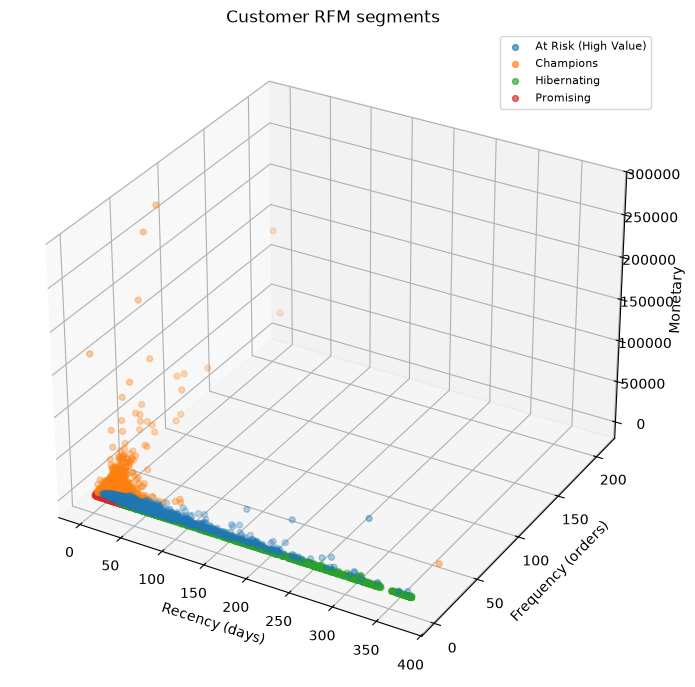

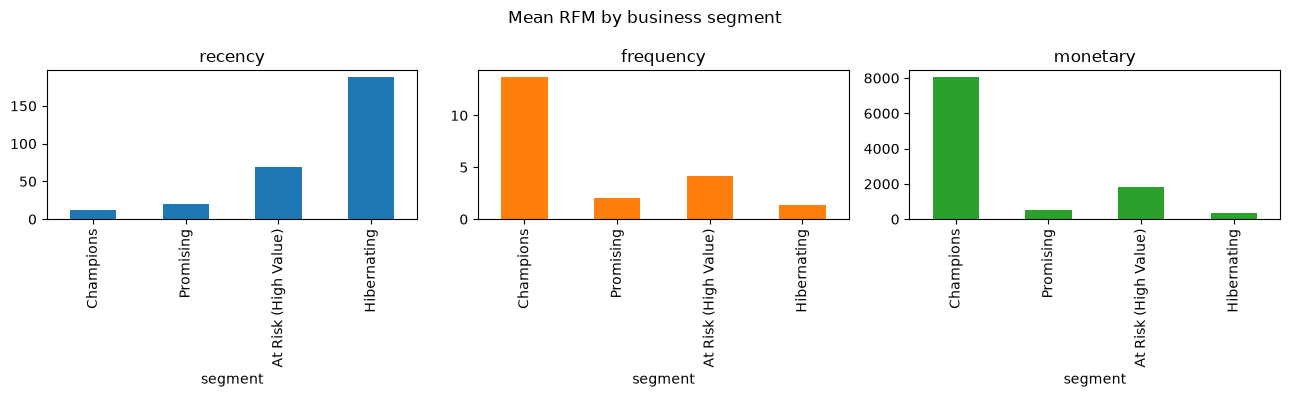

In [4]:
scatter_path, profile_path = save_segment_figures(segments)
display(Image(filename=str(scatter_path)))
display(Image(filename=str(profile_path)))